In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import geopandas as gpd
from tqdm import tqdm
import os

%load_ext autoreload
%autoreload 2

pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt
import scienceplots

# standard styles:
plt.style.use('science') # 'bmh' 'ggplot'
plt.style.use(["science", "no-latex"])  # <- important

# fra: https://github.com/dhaitz/matplotlib-stylesheets?tab=readme-ov-file
plt.style.use('https://github.com/dhaitz/matplotlib-stylesheets/raw/master/pacoty.mplstyle')

In [ ]:
# indlæser valgt bbr-datasæt med historiske observationer.
file_path = r"D:\tung_databehandling\BBR\processed\BBR_V3_Bygning_TotalDownload_csv_Bitemporal_653_registreringTil_isna_Status6_fixedKoordinater_fixedOpførelsesår_selected_cols_simpler_code.csv"
df = pd.read_csv(file_path) #, nrows=10*1e6)

In [18]:
def count_rows_in_csv(file_path):
    with open(file_path, "rb") as f:
        return sum(chunk.count(b"\n") for chunk in iter(lambda: f.read(1024*1024), b""))

rows = count_rows_in_csv(file_path)
print(f"{rows:,.0f} linjer i {file_path}")

29,448,317 linjer i D:\tung_databehandling\BBR\processed\BBR_V3_Bygning_TotalDownload_csv_Bitemporal_653_registreringTil_isna_Status6_fixedKoordinater_fixedOpførelsesår_selected_cols.csv


In [19]:
# ordner efter id, og virkningsdato, så vi senere kan kigge på ædringer over tid ved at kigge på forrige række for samme id.
df = df.sort_values(['id_namespace', 'id_lokalId', 'virkningFra']).reset_index(drop=True)
print(f"Shape: ({df.shape[0]:,.0f}, {df.shape[1]})") # output 04-02-2026: (14.118.485, 16)
print(list(df.columns))
display(df.head())

Shape: (29,448,316, 19)
['id_namespace', 'id_lokalId', 'kommunekode', 'registreringFra', 'registreringTil', 'virkningFra', 'virkningTil', 'status', 'byg021BygningensAnvendelse', 'byg026Opførelsesår', 'byg027OmTilbygningsår', 'byg038SamletBygningsareal', 'byg039BygningensSamledeBoligAreal', 'byg040BygningensSamledeErhvervsAreal', 'byg041BebyggetAreal', 'byg054AntalEtager', 'byg134KvalitetAfKoordinatsæt', 'byg404Koordinat', 'byg406Koordinatsystem']


,id_namespace,id_lokalId,kommunekode,registreringFra,registreringTil,virkningFra,virkningTil,status,byg021BygningensAnvendelse,byg026Opførelsesår,byg027OmTilbygningsår,byg038SamletBygningsareal,byg039BygningensSamledeBoligAreal,byg040BygningensSamledeErhvervsAreal,byg041BebyggetAreal,byg054AntalEtager,byg134KvalitetAfKoordinatsæt,byg404Koordinat,byg406Koordinatsystem
0,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2017-06-02T12:29:37.000000,NaN,2017-01-16T10:11:07.207000,2017-04-03T09:16:17.573000,6,420.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,3.0,POINT (530607.89 6147886.08),5.0
1,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2020-04-22T13:11:13.710515,NaN,2017-04-03T09:16:17.573000,2020-04-22T13:11:13.710515,6,420.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0
2,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2020-04-22T13:11:32.864148,NaN,2020-04-22T13:11:13.710515,2020-04-22T13:11:32.864148,6,421.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0
3,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2025-02-18T13:24:36.452648,NaN,2020-04-22T13:11:32.864148,2025-02-18T13:24:36.452648,6,421.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0
4,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2025-02-18T13:24:36.452648,NaN,2025-02-18T13:24:36.452648,NaN,6,421.0,1960.0,NaN,540.0,NaN,540.0,381.0,2.0,1.0,POINT (530607.89 6147886.08),5.0


In [20]:
# Anvend samme filter som DuckDB pipeline: kun aktuelle registreringer og faktiske bygninger
initial_rows = df.shape[0]

# Konverter registreringtil til at håndtere både NaN og tomme strenge
df['registreringTil'] = df['registreringTil'].fillna('')

mask_isna = df['registreringTil'] == ''
mask_opført = df['status'].isin([6, 7, 8])


print(df.shape[0], sum(mask_isna), sum(mask_opført))

29448316 29448316 29448316


In [21]:
# Anvend filter
df = df[
    mask_isna &  # aktuelle registreringer (ikke arkiverede)
    mask_opført   # faktiske bygninger
].reset_index(drop=True)

filtered_rows = df.shape[0]
print(f"\nFiltrer data:")
print(f"  Før: {initial_rows:,.0f} rækker")
print(f"  Efter: {filtered_rows:,.0f} rækker")
print(f"  Fjernet: {initial_rows - filtered_rows:,.0f} rækker ({(1 - filtered_rows/initial_rows)*100:.1f}%)")



Filtrer data:
  Før: 29,448,316 rækker
  Efter: 29,448,316 rækker
  Fjernet: 0 rækker (0.0%)


In [22]:
# tilføjer "modelleret_areal" dimension, som estimerer bygningens areal ud fra de tilgængelige data.
def pct_nan(series, verbose=True):
    if verbose:
        print(f'\tAndel nan i modelleret areal so far: {np.round(series.isna().mean()*100,2)}%\n')

def dan_modelleret_areal(df, verbose=True):

    """
    input: dataframe med BBR data, hvor følgende dimensioner indgår: byg038SamletBygningsareal, byg041BebyggetAreal og byg054AntalEtager
    output: samme dataframe, med ny dimension "modelleret_areal", som er udfyldt efter følgende logik:
        1) modelleret_areal <- byg038SamletBygningsareal
        2) modelleret_areal <- byg054AntalEtager * byg041BebyggetAreal (hvor byg038SamletBygningsareal er NaN)
        3) modelleret_areal <- byg041BebyggetAreal (hvor modelleret_areal stadig er NaN)
    """

    if verbose:
        print(f'Danner "modelleret_areal" dimensionen\n')

    # modelleret_areal <- samletbygningsareal
    df['modelleret_areal'] = df['byg038SamletBygningsareal']
    m_arealdata_isna = df['byg038SamletBygningsareal'].isna()
    pct_nan(df['modelleret_areal'], verbose=verbose)

    # modlleret_areal <- etager * grundareal (hvor modelleret_areal.isna() == True)
    print(f'\tGennemsnitlig m2 for udfyldte Etage*bebyggetareal: {pd.Series(df[m_arealdata_isna]['byg054AntalEtager'] * df[m_arealdata_isna]['byg041BebyggetAreal']).dropna().mean().round(2)}')
    df.loc[m_arealdata_isna, 'modelleret_areal'] = df[m_arealdata_isna]['byg054AntalEtager'] * df[m_arealdata_isna]['byg041BebyggetAreal'] 
    m_arealdata_isna = df['modelleret_areal'].isna()
    pct_nan(df['modelleret_areal'], verbose=verbose)

    # modelleret_areal <- grundareal / bebygetareal
    df.loc[m_arealdata_isna, 'modelleret_areal'] = df.loc[m_arealdata_isna,'byg041BebyggetAreal']
    m_arealdata_isna = df['modelleret_areal'].isna()
    pct_nan(df['modelleret_areal'], verbose=verbose)

    return df


df = dan_modelleret_areal(df)
df.head(5)

Danner "modelleret_areal" dimensionen

	Andel nan i modelleret areal so far: 40.64%

	Gennemsnitlig m2 for udfyldte Etage*bebyggetareal: 98.23
	Andel nan i modelleret areal so far: 40.35%

	Andel nan i modelleret areal so far: 0.1%



,id_namespace,id_lokalId,kommunekode,registreringFra,registreringTil,virkningFra,virkningTil,status,byg021BygningensAnvendelse,byg026Opførelsesår,byg027OmTilbygningsår,byg038SamletBygningsareal,byg039BygningensSamledeBoligAreal,byg040BygningensSamledeErhvervsAreal,byg041BebyggetAreal,byg054AntalEtager,byg134KvalitetAfKoordinatsæt,byg404Koordinat,byg406Koordinatsystem,modelleret_areal
0,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2017-06-02T12:29:37.000000,,2017-01-16T10:11:07.207000,2017-04-03T09:16:17.573000,6,420.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,3.0,POINT (530607.89 6147886.08),5.0,542.0
1,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2020-04-22T13:11:13.710515,,2017-04-03T09:16:17.573000,2020-04-22T13:11:13.710515,6,420.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,542.0
2,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2020-04-22T13:11:32.864148,,2020-04-22T13:11:13.710515,2020-04-22T13:11:32.864148,6,421.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,542.0
3,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2025-02-18T13:24:36.452648,,2020-04-22T13:11:32.864148,2025-02-18T13:24:36.452648,6,421.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,542.0
4,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2025-02-18T13:24:36.452648,,2025-02-18T13:24:36.452648,NaN,6,421.0,1960.0,NaN,540.0,NaN,540.0,381.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,540.0


In [23]:
# TILFØJER INDIKATOR FOR OBSERVATION HVOR ANVENDELSE ÆNDRES, SAMT DIMENSIONER FOR HVAD DEN ÆNDRES FRA OG TIL
def tilføj_dimensioner_for_ændringer_i_anvendelse(bbr):
    """
    input: BBR data med ikke-arkiverede data / aktuelle data (dvs. hvor registreringTil = NaN) 
           med følgende variable: id_namespace (str), id_lokalId (str), virkningFra (datetime) og byg021BygningensAnvendelse (numeric)
    output: samme data, med følgende nye variable:
            - I_D_byg021Anvendelse (int): indikator for ændring i byg021BygningensAnvendelse i forhold til forrige observation for samme id_lokalId (1 = der er sket en ændring, 0 = ingen ændring)
            - from_byg021Anvendelse (numeric): den tidligere kategori for byg021BygningensAnvendelse, hvor der er sket en ændring (NaN hvis ingen ændring)
            - to_byg021Anvendelse (numeric): den nye kategori for byg021BygningensAnvendelse, hvor der er sket en ændring (NaN hvis ingen ændring)
    """

    # Kolonner der tilsammen identificerer den samme bygning,
    # samt variablen vi vil undersøge for ændringer
    keys = ["id_namespace", "id_lokalId"]
    col = "byg021BygningensAnvendelse"

    # Sortér hver bygnings rækker kronologisk efter virkningFra
    bbr = bbr.sort_values(keys + ["virkningFra"]).reset_index(drop=True)

    # Hent den foregående anvendelsesværdi inden for samme bygning
    previous = bbr.groupby(keys)[col].shift()

    # False for bygningens første række, True for alle senere rækker
    not_first = bbr.groupby(keys).cumcount().gt(0)

    # En ændring forekommer, hvis:
    # 1) rækken ikke er bygningens første række, og
    # 2) nuværende og tidligere værdi er forskellige
    # To manglende værdier betragtes ikke som en ændring
    changed = not_first & ~(
        bbr[col].eq(previous)
        | (bbr[col].isna() & previous.isna())
    )

    # Indikator: True når anvendelsen ændres fra forrige række
    bbr["I_D_byg021Anvendelse"] = changed

    # Tidligere anvendelseskode, kun udfyldt på rækker med ændring
    bbr["from_byg021Anvendelse"] = previous.where(changed)

    # Ny anvendelseskode, kun udfyldt på rækker med ændring
    bbr["to_byg021Anvendelse"] = bbr[col].where(changed)
    
    return bbr


bbr_processed = tilføj_dimensioner_for_ændringer_i_anvendelse(df)

# tilføjer 'year' dimension, som vi skal bruge i vores plot senere, og som er udtrukket af virkningFra datoen.
bbr_processed['year'] = bbr_processed['virkningFra'].str[:4].astype(int)
bbr_processed.head()

,id_namespace,id_lokalId,kommunekode,registreringFra,registreringTil,virkningFra,virkningTil,status,byg021BygningensAnvendelse,byg026Opførelsesår,byg027OmTilbygningsår,byg038SamletBygningsareal,byg039BygningensSamledeBoligAreal,byg040BygningensSamledeErhvervsAreal,byg041BebyggetAreal,byg054AntalEtager,byg134KvalitetAfKoordinatsæt,byg404Koordinat,byg406Koordinatsystem,modelleret_areal,I_D_byg021Anvendelse,from_byg021Anvendelse,to_byg021Anvendelse,year
0,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2017-06-02T12:29:37.000000,,2017-01-16T10:11:07.207000,2017-04-03T09:16:17.573000,6,420.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,3.0,POINT (530607.89 6147886.08),5.0,542.0,False,NaN,NaN,2017
1,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2020-04-22T13:11:13.710515,,2017-04-03T09:16:17.573000,2020-04-22T13:11:13.710515,6,420.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,542.0,False,NaN,NaN,2017
2,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2020-04-22T13:11:32.864148,,2020-04-22T13:11:13.710515,2020-04-22T13:11:32.864148,6,421.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,542.0,True,420.0,421.0,2020
3,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2025-02-18T13:24:36.452648,,2020-04-22T13:11:32.864148,2025-02-18T13:24:36.452648,6,421.0,1960.0,NaN,542.0,NaN,542.0,378.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,542.0,False,NaN,NaN,2020
4,http://data.gov.dk/bbr/bygning,00000000-1822-4d89-8bd8-c8eca3065c5f,621,2025-02-18T13:24:36.452648,,2025-02-18T13:24:36.452648,NaN,6,421.0,1960.0,NaN,540.0,NaN,540.0,381.0,2.0,1.0,POINT (530607.89 6147886.08),5.0,540.0,False,NaN,NaN,2025


In [ ]:
# gem datasæt med modelleret_data dimension og dummies for skift
file_path = r"D:\tung_databehandling\BBR\derived\modelleret_areal_fixedKoordinat_fixedOpførelsesår_simpler_code.csv"
bbr_processed.to_csv(file_path, index=False)

In [5]:
# henter færdigbehandlet tabel (som er skabt ved at køre overstående kode)
bbr_processed = pd.read_csv(file_path)
print(bbr_processed.shape, "\n", bbr_processed.columns)

Index(['id_namespace', 'id_lokalId', 'kommunekode', 'registreringFra',
       'registreringTil', 'virkningFra', 'virkningTil', 'status',
       'byg021BygningensAnvendelse', 'byg026Opførelsesår',
       'byg027OmTilbygningsår', 'byg038SamletBygningsareal',
       'byg039BygningensSamledeBoligAreal',
       'byg040BygningensSamledeErhvervsAreal', 'byg041BebyggetAreal',
       'byg054AntalEtager', 'byg134KvalitetAfKoordinatsæt', 'byg404Koordinat',
       'byg406Koordinatsystem', 'modelleret_areal', 'I_D_byg021Anvendelse',
       'from_byg021Anvendelse', 'to_byg021Anvendelse', 'year'],
      dtype='object') 
 (29448316, 24)


In [6]:
def plot_antal_aktive_bygninger(df, year_range, figure_name="figure.png"):
    antal = []

    df['byg026Opførelsesår'] = pd.to_numeric(df['byg026Opførelsesår'], errors="coerce")

    # Ensure virkningTil is datetime if it isn't already
    df['virkningTil'] = pd.to_datetime(df['virkningTil'], errors="coerce")

    # Precompute parts that don't depend on year
    mask_status = (df['status'] == 6)
    opfoer = df['byg026Opførelsesår']
    virkningTil = df['virkningTil']

    for yyyy in tqdm(year_range):
        yyyy_dt = pd.Timestamp(f"{yyyy}-01-01")

        mask = (
            mask_status
            & (opfoer <= yyyy)
            & ((virkningTil >= yyyy_dt) | virkningTil.isna())
        )

        # unikke id'er som er opført (for at undgå dobbelttælling af bygninger der fx har skiftet anvendelse)
        antal.append(df.loc[mask, 'id_lokalId'].nunique())

    plt.figure(figsize=(9, 7))
    plt.plot(list(year_range), antal)
    plt.title("Antal aktuelle bygninger i BBR per år")
    plt.savefig(f"P:/cmo/TFPogTaethed/BBR/output/{figure_name}", dpi=300, bbox_inches="tight")

    # kombiner år og antal i en dataframe der outputtes
    return pd.DataFrame({'year': list(year_range), 'count': antal})


  0%|          | 0/57 [00:00<?, ?it/s]

    year    count
41  2021  4826887
42  2021  4826887
43  2021  4826887
44  2022  4846676
45  2022  4846676
46  2022  4846676
47  2023  4858414
48  2023  4858414
49  2023  4858414
50  2024  4858554
51  2024  4858554
52  2024  4858554
53  2025  4861653
54  2025  4861653
55  2025  4861653
56  2026  4839575


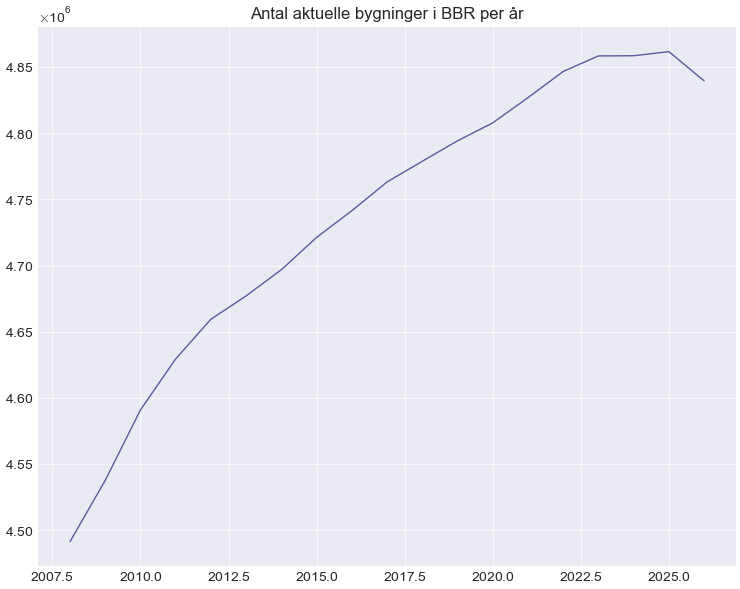

In [7]:
antal_data = plot_antal_aktive_bygninger(
    bbr_processed,
    year_range=np.linspace(2008,2026,57).astype(int),
    figure_name="Antal_Bygninger.png"
)
# udskriv evt. bestemte år du vil undersøge nærmere.
print(antal_data[antal_data['year'] > 2020])

  0%|          | 0/439 [00:00<?, ?it/s]

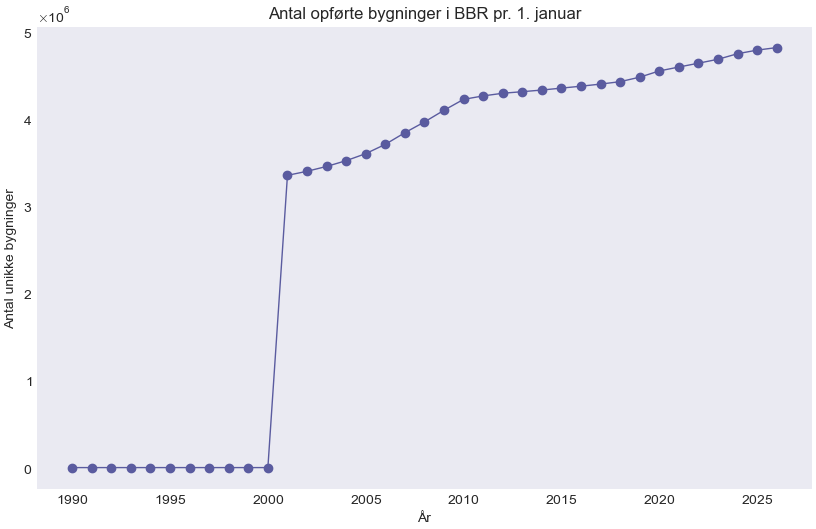

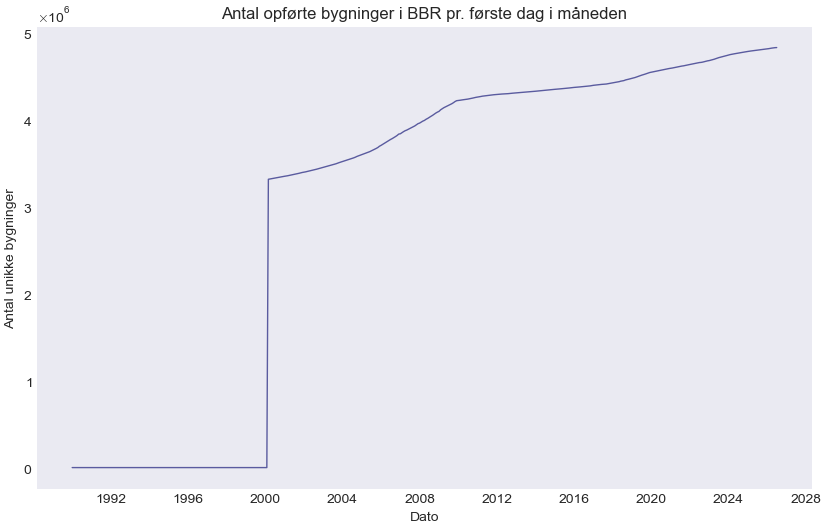

(1990-01-01 00:00:00+00:00          0
 1990-02-01 00:00:00+00:00          0
 1990-03-01 00:00:00+00:00          0
 1990-04-01 00:00:00+00:00          0
 1990-05-01 00:00:00+00:00          0
                               ...   
 2026-03-01 00:00:00+00:00    4826146
 2026-04-01 00:00:00+00:00    4828955
 2026-05-01 00:00:00+00:00    4831605
 2026-06-01 00:00:00+00:00    4833989
 2026-07-01 00:00:00+00:00    4834776
 Freq: MS, Name: antal_bygninger, Length: 439, dtype: int64,
 1990-01-01 00:00:00+00:00          0
 1991-01-01 00:00:00+00:00          0
 1992-01-01 00:00:00+00:00          0
 1993-01-01 00:00:00+00:00          0
 1994-01-01 00:00:00+00:00          0
 1995-01-01 00:00:00+00:00          0
 1996-01-01 00:00:00+00:00          0
 1997-01-01 00:00:00+00:00          0
 1998-01-01 00:00:00+00:00          0
 1999-01-01 00:00:00+00:00          0
 2000-01-01 00:00:00+00:00          0
 2001-01-01 00:00:00+00:00    3353438
 2002-01-01 00:00:00+00:00    3399935
 2003-01-01 00:00:00+00:00 

In [ ]:
def plot_antal_bygninger_i_virkning_snapshots(df, start="1990-01-01", end="2026-07-01"):
    d = df.copy()

    # Harmonise datetime columns
    for column in ["registreringFra", "registreringTil", "virkningFra", "virkningTil"]:
        d[column] = pd.to_datetime(d[column], errors="coerce", utc=True)

    d["status"] = pd.to_numeric(d["status"], errors="coerce")

    # Current registered knowledge about completed buildings
    d = d.loc[
        d["registreringTil"].isna() & d["status"].eq(6)
        & d["virkningFra"].notna() & d["id_lokalId"].notna()
    ].copy()

    snapshot_dates = pd.date_range(
        pd.to_datetime(start, utc=True), pd.to_datetime(end, utc=True), freq="MS"
    )

    antal_per_maaned = []
    for snapshot_date in tqdm(snapshot_dates):
        active = d.loc[
            d["virkningFra"].le(snapshot_date)
            & (d["virkningTil"].isna() | d["virkningTil"].gt(snapshot_date))
        ]
        antal_per_maaned.append(active["id_lokalId"].nunique())

    monthly = pd.Series(antal_per_maaned, index=snapshot_dates, name="antal_bygninger")
    yearly = monthly.loc[monthly.index.month == 1]

    # Annual plot
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(yearly.index.year, yearly.values, marker="o")
    ax.set_title("Antal opførte bygninger i BBR pr. 1. januar")
    ax.set_xlabel("År")
    ax.set_ylabel("Antal unikke bygninger")
    ax.grid()
    fig.savefig(
        "P:/cmo/TFPogTaethed/BBR/output/Antal_Bygninger_i_Virkning_Snapshots.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

    # Monthly plot
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(monthly.index, monthly.values)
    ax.set_title("Antal opførte bygninger i BBR pr. første dag i måneden")
    ax.set_xlabel("Dato")
    ax.set_ylabel("Antal unikke bygninger")
    ax.grid()
    fig.savefig(
        "P:/cmo/TFPogTaethed/BBR/output/Antal_Bygninger_i_Virkning_Snapshots_Maaned.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

    return monthly, yearly


plot_antal_bygninger_i_virkning_snapshots(bbr_processed)

Rows after filtering: 29,448,316
Unique buildings after filtering: 5,245,724


C:\Users\cam\AppData\Local\Temp\ipykernel_12812\560753856.py:56: UserWarning: Converting to Period representation will drop timezone information.
  start_date = d["virkningFra"].min().to_period("M").start_time.tz_localize("UTC")
C:\Users\cam\AppData\Local\Temp\ipykernel_12812\560753856.py:59: UserWarning: Converting to Period representation will drop timezone information.
  end_date = end_date.to_period("M").start_time.tz_localize("UTC")


Calculating months:   0%|          | 0/317 [00:00<?, ?it/s]

Calculating years:   0%|          | 0/27 [00:00<?, ?it/s]

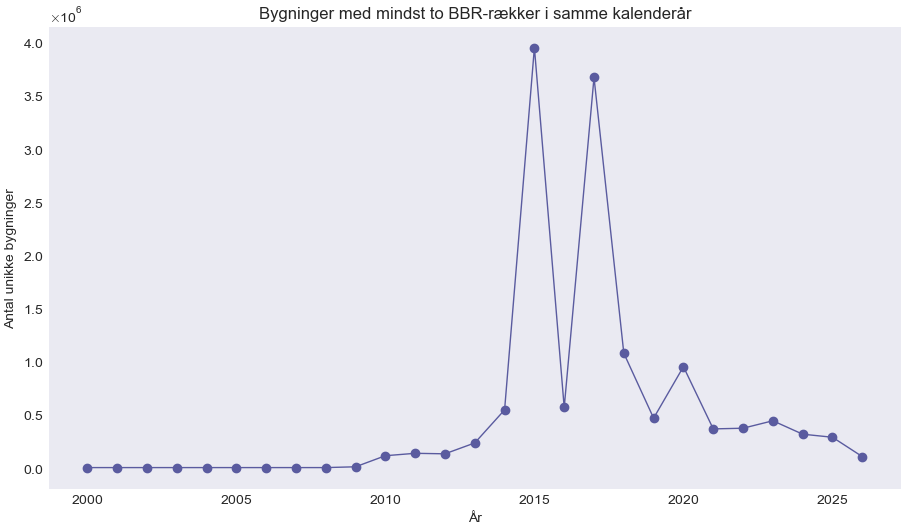

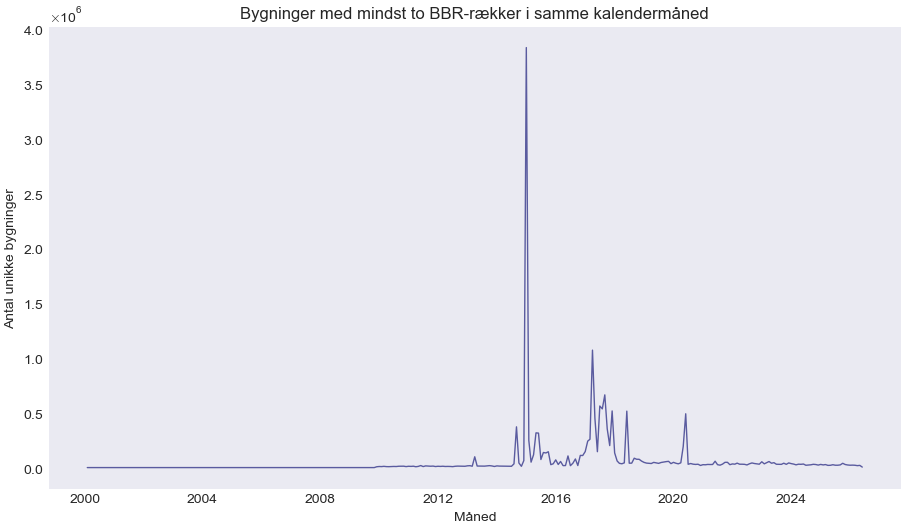

In [32]:
# Plot ændringer i bygningers registrering over tid. altås hvis der er to rækker som overlapper inden for samme år fx så har bygningen skiftet en variabel i løbet af året. Som vi vil se er dette ofte koordinatsættet.
def plot_buildings_with_multiple_rows(
    df, id_col="id_lokalId", apply_base_filter=True,
    output_folder="P:/cmo/TFPogTaethed/BBR/output",
):
    """
    Counts buildings that have at least two BBR rows overlapping the same:

        1. calendar month
        2. calendar year

    A row overlaps a period when:

        virkningFra < period_end

    and:

        virkningTil > period_start
        or virkningTil is missing (det samme som at den stadig er aktiv)

    Important:
    This does not necessarily mean that two rows are simultaneously valid
    on the exact same day. It means that at least two rows belonging to the
    same building touch the same calendar month or year.

    This is useful for diagnosing spikes caused by changes/version rows.
    """
    d = df.copy()

    # Prepare variables
    for col in ["virkningFra", "virkningTil"]:
        d[col] = pd.to_datetime(d[col], errors="coerce", utc=True)

    if "registreringTil" in d.columns:
        d["registreringTil"] = pd.to_datetime(
            d["registreringTil"], errors="coerce", utc=True
        )
    if "status" in d.columns:
        d["status"] = pd.to_numeric(d["status"], errors="coerce")

    d = d.loc[d[id_col].notna() & d["virkningFra"].notna()].copy()

    # Optional BBR base filter
    if apply_base_filter:
        if "registreringTil" not in d.columns:
            raise KeyError("apply_base_filter=True requires the column 'registreringTil'.")
        if "status" not in d.columns:
            raise KeyError("apply_base_filter=True requires the column 'status'.")

        d = d.loc[d["registreringTil"].isna() & d["status"].eq(6)].copy()

    print(f"Rows after filtering: {len(d):,}")
    print(f"Unique buildings after filtering: {d[id_col].nunique():,}")

    # Determine time range
    start_date = d["virkningFra"].min().to_period("M").start_time.tz_localize("UTC")
    latest_start = d["virkningFra"].max()
    end_date = max(latest_start, d["virkningTil"].max()) if d["virkningTil"].notna().any() else latest_start
    end_date = end_date.to_period("M").start_time.tz_localize("UTC")

    # Count buildings with multiple overlapping rows
    def count_multiple_rows(period_start, period_end):
        overlapping = d.loc[
            d["virkningFra"].lt(period_end)
            & (d["virkningTil"].isna() | d["virkningTil"].gt(period_start))
        ]
        rows_per_building = overlapping.groupby(id_col).size()
        multiple = rows_per_building.loc[rows_per_building.ge(2)]

        return {
            "buildings_with_multiple_rows": int(multiple.size),
            "extra_rows": int((multiple - 1).sum()),
            "rows_for_changed_buildings": int(multiple.sum()),
            "maximum_rows_one_building": int(multiple.max()) if not multiple.empty else 0,
        }

    # Monthly calculation
    month_starts = pd.date_range(start=start_date, end=end_date, freq="MS", tz="UTC")
    monthly_results = []

    for month_start in tqdm(month_starts, desc="Calculating months"):
        result = count_multiple_rows(
            period_start=month_start,
            period_end=month_start + pd.offsets.MonthBegin(1),
        )
        result["date"] = month_start
        monthly_results.append(result)

    monthly = pd.DataFrame(monthly_results).set_index("date").sort_index()

    # Annual calculation
    years = range(d["virkningFra"].dt.year.min(), end_date.year + 1)
    yearly_results = []

    for year in tqdm(years, desc="Calculating years"):
        result = count_multiple_rows(
            period_start=pd.Timestamp(year=year, month=1, day=1, tz="UTC"),
            period_end=pd.Timestamp(year=year + 1, month=1, day=1, tz="UTC"),
        )
        result["year"] = year
        yearly_results.append(result)

    yearly = pd.DataFrame(yearly_results).set_index("year").sort_index()

    # Plot annual results
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(yearly.index, yearly["buildings_with_multiple_rows"], marker="o")
    ax.set_title("Bygninger med mindst to BBR-rækker i samme kalenderår")
    ax.set_xlabel("År")
    ax.set_ylabel("Antal unikke bygninger")
    ax.grid()
    fig.savefig(
        f"{output_folder}/Bygninger_med_flere_BBR_raekker_per_aar.png",
        dpi=300, bbox_inches="tight",
    )
    plt.show()

    # Plot monthly results
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(monthly.index, monthly["buildings_with_multiple_rows"])
    ax.set_title("Bygninger med mindst to BBR-rækker i samme kalendermåned")
    ax.set_xlabel("Måned")
    ax.set_ylabel("Antal unikke bygninger")
    ax.grid()
    fig.savefig(
        f"{output_folder}/Bygninger_med_flere_BBR_raekker_per_maaned.png",
        dpi=300, bbox_inches="tight",
    )
    plt.show()

    # Save results
    yearly.to_csv(
        f"{output_folder}/Bygninger_med_flere_BBR_raekker_per_aar.csv",
        sep=";", encoding="utf-8-sig",
    )
    monthly.to_csv(
        f"{output_folder}/Bygninger_med_flere_BBR_raekker_per_maaned.csv",
        sep=";", encoding="utf-8-sig",
    )

    return monthly, yearly


monthly_multiple, yearly_multiple = plot_buildings_with_multiple_rows(
    bbr_processed, id_col="id_lokalId", apply_base_filter=True
)

In [33]:
# den voldsomme ændring sker i 2015 hvor BBR opdateres. I følge BBR's officielle dokumentation kan man ikke stole på virkningFra / Til før 2017.
print(monthly_multiple.sort_values("buildings_with_multiple_rows", ascending=False).head(5))

                           buildings_with_multiple_rows  extra_rows  \
date                                                                  
2015-01-01 00:00:00+00:00                       3834446     6734509   
2017-04-01 00:00:00+00:00                       1072291     1253447   
2017-09-01 00:00:00+00:00                        663835      675602   
2017-07-01 00:00:00+00:00                        562061      632574   
2017-08-01 00:00:00+00:00                        536164      546596   

                           rows_for_changed_buildings  \
date                                                    
2015-01-01 00:00:00+00:00                    10568955   
2017-04-01 00:00:00+00:00                     2325738   
2017-09-01 00:00:00+00:00                     1339437   
2017-07-01 00:00:00+00:00                     1194635   
2017-08-01 00:00:00+00:00                     1082760   

                           maximum_rows_one_building  
date                                           

In [34]:
print(bbr_processed["byg404Koordinat"])

0                         POINT (530607.89 6147886.08)
1                         POINT (530607.89 6147886.08)
2                         POINT (530607.89 6147886.08)
3                         POINT (530607.89 6147886.08)
4                         POINT (530607.89 6147886.08)
                               ...                    
29448311                  POINT (538538.05 6261743.36)
29448312                  POINT (538538.05 6261743.36)
29448313                  POINT (538539.15 6261734.96)
29448314                  POINT (538539.15 6261734.96)
29448315    POINT (538540.377734375 6261744.125820313)
Name: byg404Koordinat, Length: 29448316, dtype: object


Rows: 29,448,316
Buildings: 5,245,724
Variables: 14


Years:   0%|          | 0/27 [00:00<?, ?it/s]

Months:   0%|          | 0/24 [00:00<?, ?it/s]


Variables changing most in 2015:
                            variable  buildings_with_different_values  buildings_with_multiple_rows  share_changed  year
        byg134KvalitetAfKoordinatsæt                          2837745                       3950127       0.718393  2015
                     byg404Koordinat                          1965232                       3950127       0.497511  2015
                    modelleret_areal                            32265                       3950127       0.008168  2015
                 byg041BebyggetAreal                            31195                       3950127       0.007897  2015
           byg038SamletBygningsareal                            26680                       3950127       0.006754  2015
   byg039BygningensSamledeBoligAreal                            22795                       3950127       0.005771  2015
               byg027OmTilbygningsår                            10647                       3950127       0.002695  201

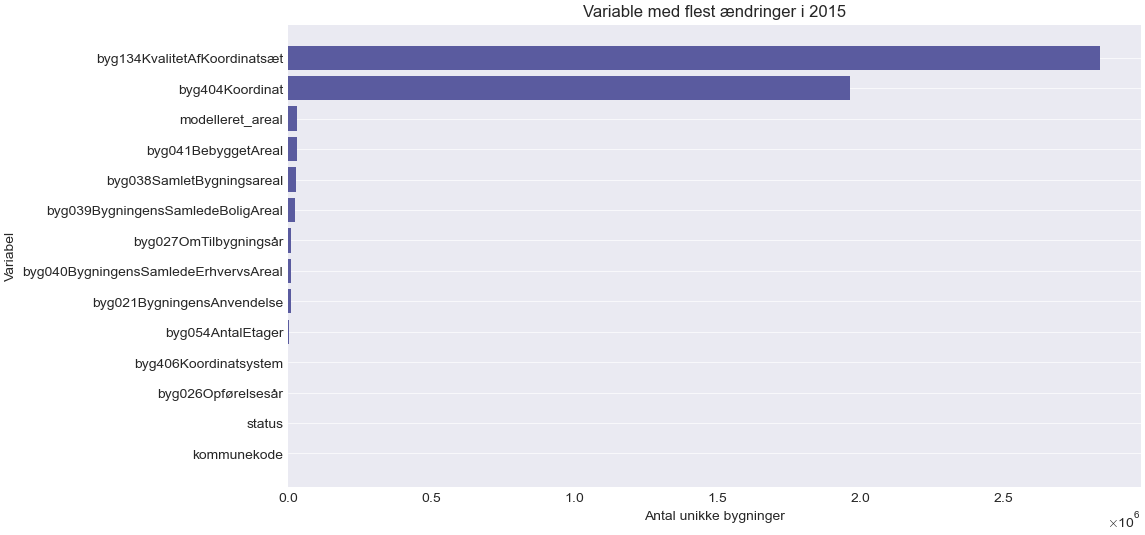

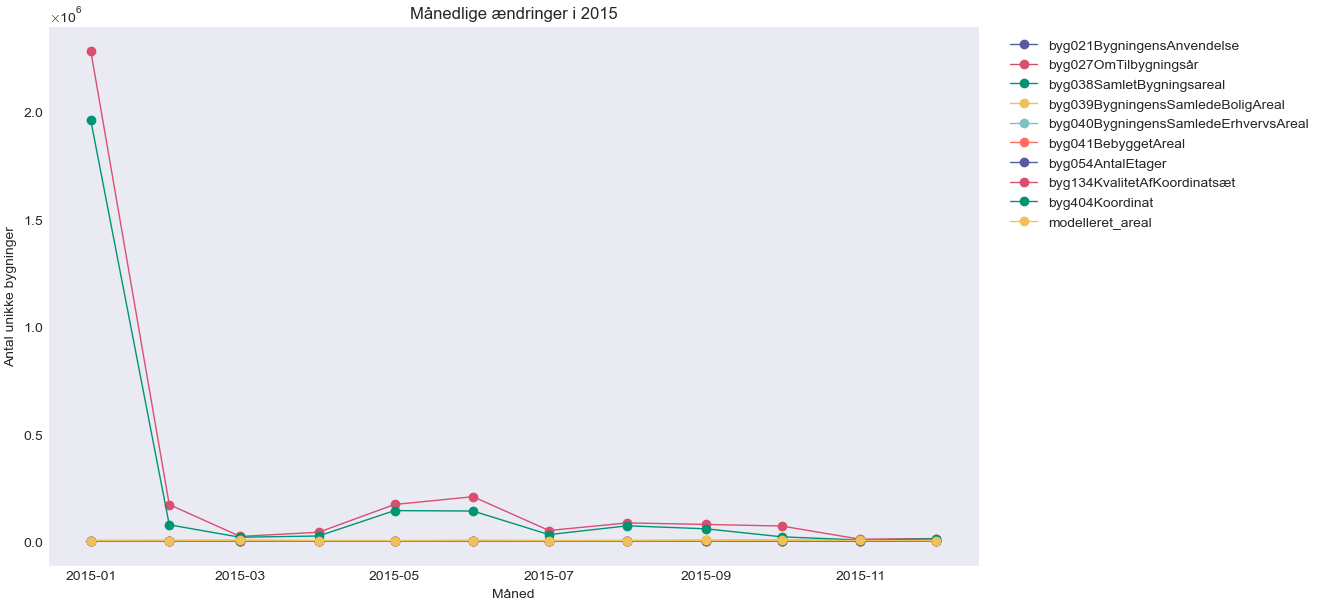


Variables changing most in 2017:
                            variable  buildings_with_different_values  buildings_with_multiple_rows  share_changed  year
        byg134KvalitetAfKoordinatsæt                          1286706                       3669295   3.506685e-01  2017
                     byg404Koordinat                           589665                       3669295   1.607025e-01  2017
          byg021BygningensAnvendelse                            83897                       3669295   2.286461e-02  2017
                    modelleret_areal                            33289                       3669295   9.072315e-03  2017
                 byg041BebyggetAreal                            32173                       3669295   8.768169e-03  2017
           byg038SamletBygningsareal                            26816                       3669295   7.308216e-03  2017
   byg039BygningensSamledeBoligAreal                            22335                       3669295   6.087000e-03  201

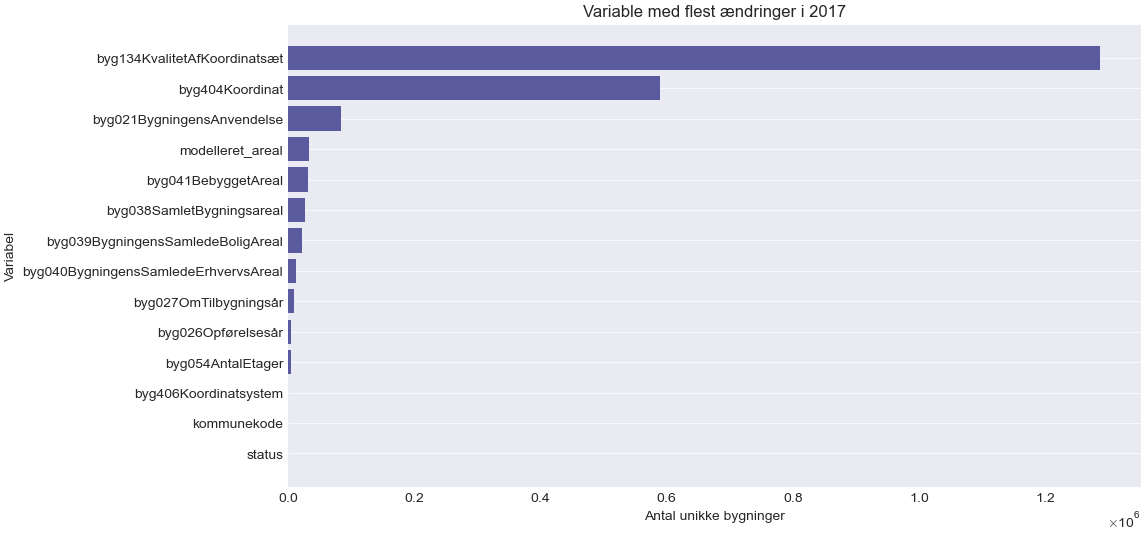

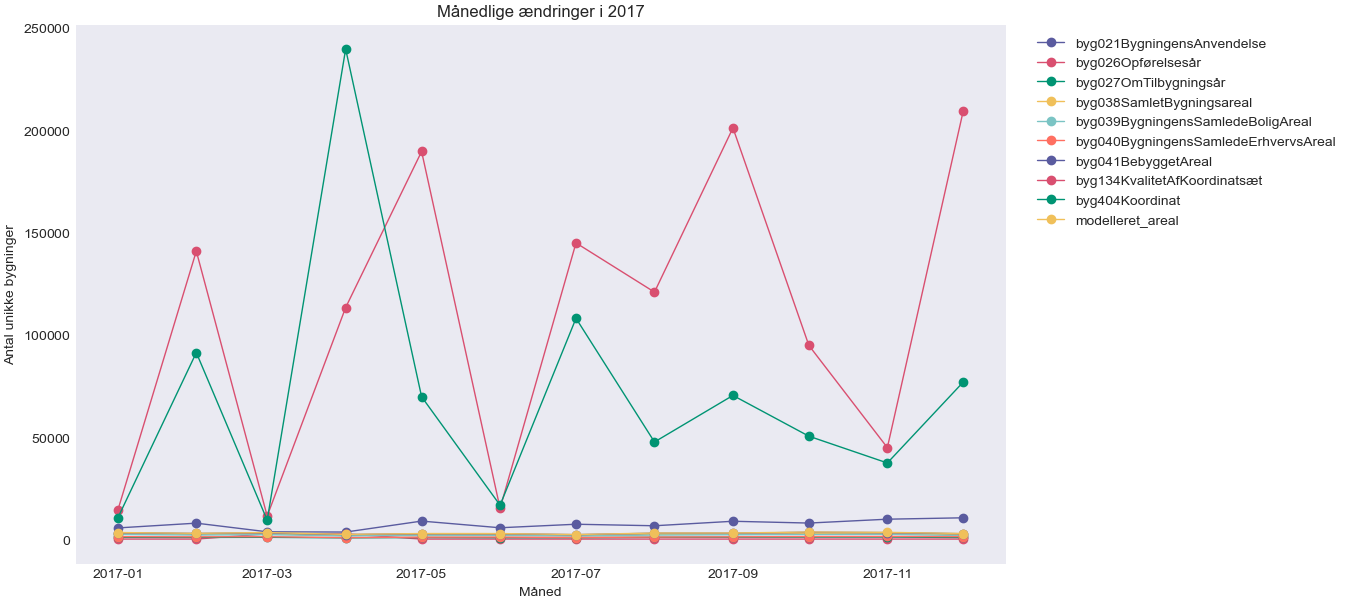

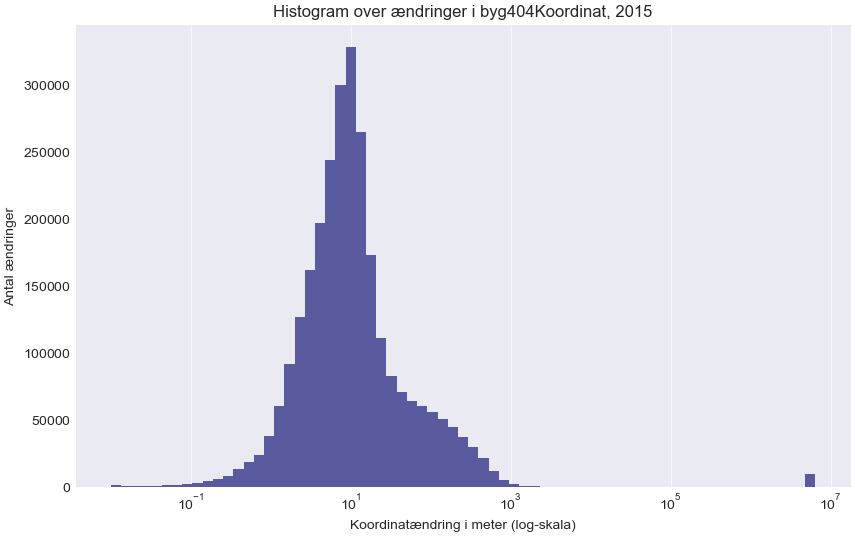


Størrelse og fordeling for byg404Koordinat, 2015:
 year        variable  unit  number_of_changes  mean_absolute_change  std_absolute_change  min      p01      p05      p25   median       p75        p95        p99          max  mean_signed_change     mean_dx      mean_dy
 2015 byg404Koordinat meter            2725034          20768.346749        356880.105471 0.01 0.295466 1.180678 4.276786 9.089356 19.770653 193.320996 550.586443 6.425854e+06                 NaN 1861.542735 20416.628342


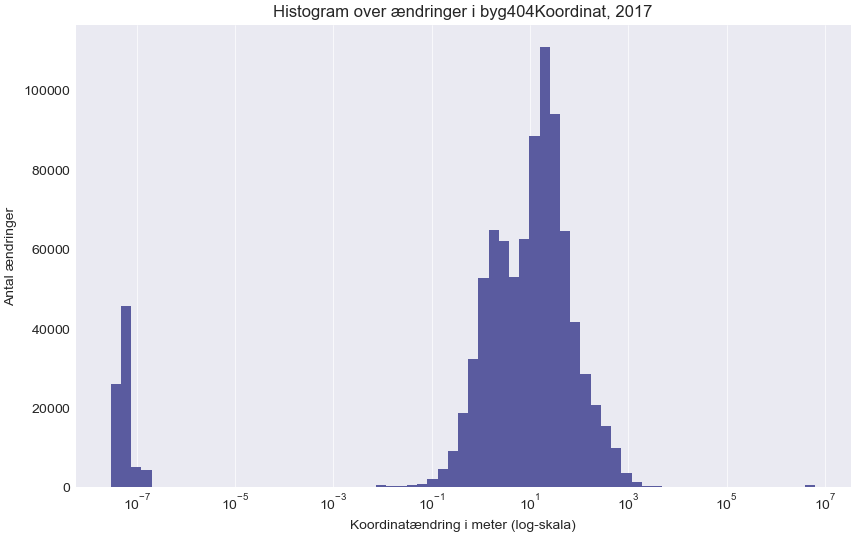


Størrelse og fordeling for byg404Koordinat, 2017:
 year        variable  unit  number_of_changes  mean_absolute_change  std_absolute_change          min          p01          p05      p25    median       p75        p95        p99          max  mean_signed_change    mean_dx     mean_dy
 2017 byg404Koordinat meter             924232           3143.866573        138925.069605 2.980232e-08 4.004687e-08 5.029142e-08 1.780028 10.871217 31.899841 190.405482 576.110406 6.414635e+06                 NaN 339.958653 3040.742452


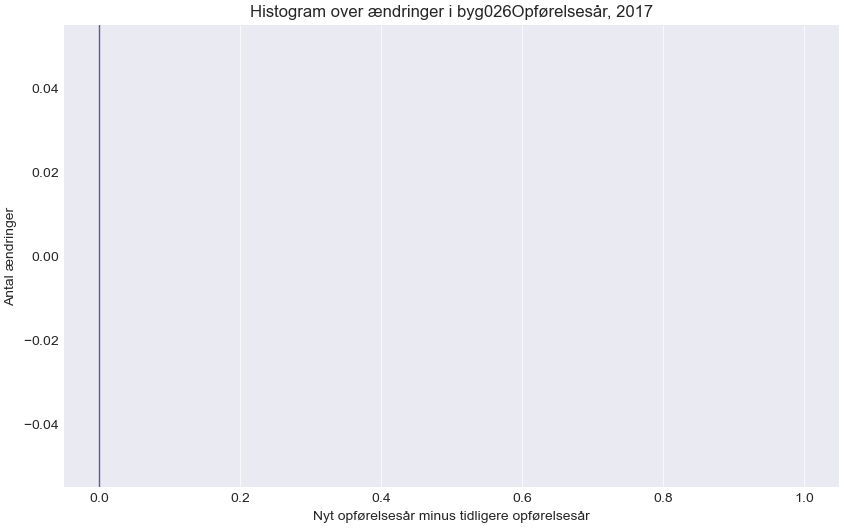


Størrelse og fordeling for byg026Opførelsesår, 2017:
 year           variable unit  number_of_changes  mean_absolute_change  std_absolute_change  min  p01  p05  p25  median  p75  p95  p99  max  mean_signed_change  mean_dx  mean_dy
 2017 byg026Opførelsesår   år                  0                   NaN                  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN                 NaN      NaN      NaN


In [ ]:
# Hvor mange af de skiftende bygningsrækker har ændrede variable, og hvilke variable ændres mest?
# Særligt interessant er 2015 og 2017, hvor mange bygninger tilsyneladende får nye BBR-rækker.
# For byg404Koordinat og byg026Opførelsesår beregnes desuden ændringernes størrelse og histogrammer.

import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm

def analyze_characteristic_changes_simple(
    df, id_col="id_lokalId", apply_base_filter=True, focus_years=(2015, 2017),
    magnitude_vars=None, top_n=20, compare_cols=None, exclude_cols=None,
    analyze_all_months=False, output_folder="P:/cmo/TFPogTaethed/BBR/output"
):
    os.makedirs(output_folder, exist_ok=True)
    focus_years = (focus_years,) if isinstance(focus_years, int) else tuple(focus_years)
    magnitude_vars = magnitude_vars or {
        2015: ["byg404Koordinat"],
        2017: ["byg404Koordinat", "byg026Opførelsesår"]
    }
    d = df.copy()

    # Klargør dato- og statusvariable
    for c in ["virkningFra", "virkningTil", "registreringFra", "registreringTil"]:
        if c in d: d[c] = pd.to_datetime(d[c], errors="coerce", utc=True)
    if "status" in d: d["status"] = pd.to_numeric(d["status"], errors="coerce")

    # Fjern manglende ID/startdato, dubletter og eventuelt arkiverede/ikke-opførte rækker
    d = d[d[id_col].notna() & d["virkningFra"].notna()].drop_duplicates()
    if apply_base_filter: d = d[d["registreringTil"].isna() & d["status"].eq(6)]

    # Vælg egentlige bygningsvariable
    technical = {
        id_col, "virkningFra", "virkningTil", "registreringFra", "registreringTil",
        "id_namespace", "objektType", "datafordelerOpdateringstid"
    } | set(exclude_cols or [])
    compare_cols = ([c for c in d if c not in technical] if compare_cols is None
                    else [c for c in compare_cols if c in d and c not in technical])

    print(f"Rows: {len(d):,}\nBuildings: {d[id_col].nunique():,}\nVariables: {len(compare_cols):,}")

    # Find antal bygninger hvor hver variabel har forskellige værdier i perioden
    def analyze_period(start, end, name, value):
        x = d[d["virkningFra"].lt(end) & (d["virkningTil"].isna() | d["virkningTil"].gt(start))]
        ids = x.groupby(id_col).size().loc[lambda s: s.ge(2)].index
        x = x[x[id_col].isin(ids)]
        r = (x.groupby(id_col)[compare_cols].nunique(dropna=False).ge(2).sum()
             .rename("buildings_with_different_values").rename_axis("variable").reset_index())
        r["buildings_with_multiple_rows"] = len(ids)
        r["share_changed"] = r["buildings_with_different_values"] / len(ids) if len(ids) else 0
        r[name] = value
        return r

    # Analyser alle år
    first_year = int(d["virkningFra"].dt.year.min())
    last_date = pd.concat([d["virkningFra"], d["virkningTil"].dropna()]).max()
    last_year = int(last_date.year)
    annual = pd.concat([
        analyze_period(pd.Timestamp(f"{y}-01-01", tz="UTC"),
                       pd.Timestamp(f"{y+1}-01-01", tz="UTC"), "year", y)
        for y in tqdm(range(first_year, last_year + 1), desc="Years")
    ], ignore_index=True)

    # Analyser enten alle måneder eller kun månederne i fokusårene
    if analyze_all_months:
        first = d["virkningFra"].min()
        months = pd.date_range(pd.Timestamp(first.year, first.month, 1, tz="UTC"),
                               pd.Timestamp(last_date.year, last_date.month, 1, tz="UTC"), freq="MS")
    else:
        months = pd.DatetimeIndex([
            m for y in focus_years
            for m in pd.date_range(f"{y}-01-01", f"{y}-12-01", freq="MS", tz="UTC")
        ])

    monthly = pd.concat([
        analyze_period(m, m + pd.offsets.MonthBegin(), "month", m)
        for m in tqdm(months, desc="Months")
    ], ignore_index=True)

    # Rangeringer og figurer for fokusårene
    rankings = {}
    for y in focus_years:
        ranking = (annual[annual["year"].eq(y)]
                   .sort_values("buildings_with_different_values", ascending=False)
                   .reset_index(drop=True))
        rankings[y] = ranking
        print(f"\nVariables changing most in {y}:\n{ranking.head(top_n).to_string(index=False)}")

        # Søjlediagram over variable der ændres mest
        p = ranking.head(top_n).sort_values("buildings_with_different_values")
        fig, ax = plt.subplots(figsize=(11, max(6, len(p) * .35)))
        ax.barh(p["variable"], p["buildings_with_different_values"])
        ax.set(title=f"Variable med flest ændringer i {y}",
               xlabel="Antal unikke bygninger", ylabel="Variabel")
        ax.grid(axis="x")
        fig.savefig(f"{output_folder}/Variable_med_flest_aendringer_{y}.png",
                    dpi=300, bbox_inches="tight")
        plt.show()

        # Månedlig udvikling for de 10 mest ændrede variable
        top = ranking.head(min(10, top_n))["variable"]
        mp = monthly[monthly["variable"].isin(top) & monthly["month"].dt.year.eq(y)]
        fig, ax = plt.subplots(figsize=(12, 7))
        for v, g in mp.groupby("variable"):
            ax.plot(g["month"], g["buildings_with_different_values"], marker="o", label=v)
        ax.set(title=f"Månedlige ændringer i {y}",
               xlabel="Måned", ylabel="Antal unikke bygninger")
        ax.grid()
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
        fig.savefig(f"{output_folder}/Variable_aendringer_per_maaned_{y}.png",
                    dpi=300, bbox_inches="tight")
        plt.show()

        ranking.to_csv(f"{output_folder}/focus_year_ranking_{y}.csv",
                       sep=";", index=False, encoding="utf-8-sig")

    # Sortér rækker kronologisk, så hver værdi kan sammenlignes med bygningens forrige række
    sort_cols = [id_col, "virkningFra"] + (["registreringFra"] if "registreringFra" in d else [])
    s = d.sort_values(sort_cols).copy()
    summaries, distributions = {}, {}

    for y, var in [
        (y, var)
        for y, variables in magnitude_vars.items()
        for var in ([variables] if isinstance(variables, str) else variables)
    ]:
        if var not in s:
            print(f"\n{var} findes ikke i datasættet.")
            continue

        # Sammenlign kun rækker der starter i fokusåret med bygningens foregående række
        x = s[[id_col, "virkningFra", var]].copy()
        x["previous"] = x.groupby(id_col)[var].shift()
        x = x[x["virkningFra"].dt.year.eq(y) & x[var].notna() & x["previous"].notna()].copy()

        if var == "byg404Koordinat":
            # Udtræk X og Y fra eksempelvis "POINT (530506.29 6147812.08)"
            new = x[var].astype(str).str.extract(r"POINT(?: Z)?\s*\(\s*([-+0-9.eE]+)\s+([-+0-9.eE]+)")
            old = x["previous"].astype(str).str.extract(r"POINT(?: Z)?\s*\(\s*([-+0-9.eE]+)\s+([-+0-9.eE]+)")
            dx = pd.to_numeric(new[0], errors="coerce") - pd.to_numeric(old[0], errors="coerce")
            dy = pd.to_numeric(new[1], errors="coerce") - pd.to_numeric(old[1], errors="coerce")
            changes = pd.DataFrame({"change": np.hypot(dx, dy), "dx": dx, "dy": dy}).dropna()
            changes = changes[changes["change"].gt(0)]
            values, unit = changes["change"], "meter"

            # Histogram med logaritmisk x-akse, så både små og store flytninger kan ses
            fig, ax = plt.subplots(figsize=(10, 6))
            bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 70)
            ax.hist(values, bins=bins)
            ax.set_xscale("log")
            ax.set(title=f"Histogram over ændringer i {var}, {y}",
                   xlabel="Koordinatændring i meter (log-skala)", ylabel="Antal ændringer")
            distribution = pd.cut(values, [0, .01, .1, 1, 10, 100, 1_000, 10_000, np.inf],
                                  include_lowest=True).value_counts(sort=False)

        else:
            # For opførelsesår måles både fortegnet og absolut ændring
            new, old = pd.to_numeric(x[var], errors="coerce"), pd.to_numeric(x["previous"], errors="coerce")
            signed = (new - old).dropna()
            signed = signed[signed.ne(0)]
            values, unit = signed.abs(), "år"

            # Histogrammet afgrænses til 1.-99.-percentilen, så ekstreme fejl ikke skjuler hovedfordelingen
            lower, upper = signed.quantile([.01, .99])
            shown = signed[signed.between(lower, upper)]
            fig, ax = plt.subplots(figsize=(10, 6))
            ax.hist(shown, bins=min(80, max(10, int(shown.nunique()))))
            ax.axvline(0, linewidth=1)
            ax.set(title=f"Histogram over ændringer i {var}, {y}",
                   xlabel="Nyt opførelsesår minus tidligere opførelsesår", ylabel="Antal ændringer")
            distribution = signed.value_counts().sort_index()

        ax.grid(axis="y")
        fig.savefig(f"{output_folder}/Histogram_{var}_{y}.png", dpi=300, bbox_inches="tight")
        plt.show()

        # Beskriv ændringernes størrelse og spredning
        q = values.quantile([.01, .05, .25, .50, .75, .95, .99])
        summary = pd.DataFrame([{
            "year": y, "variable": var, "unit": unit, "number_of_changes": len(values),
            "mean_absolute_change": values.mean(), "std_absolute_change": values.std(),
            "min": values.min(), "p01": q.loc[.01], "p05": q.loc[.05],
            "p25": q.loc[.25], "median": q.loc[.50], "p75": q.loc[.75],
            "p95": q.loc[.95], "p99": q.loc[.99], "max": values.max(),
            "mean_signed_change": signed.mean() if var != "byg404Koordinat" else np.nan,
            "mean_dx": changes["dx"].mean() if var == "byg404Koordinat" else np.nan,
            "mean_dy": changes["dy"].mean() if var == "byg404Koordinat" else np.nan
        }])

        summaries[(y, var)] = summary
        distributions[(y, var)] = distribution.rename("count").rename_axis("change").reset_index()
        print(f"\nStørrelse og fordeling for {var}, {y}:\n{summary.to_string(index=False)}")

        summary.to_csv(f"{output_folder}/magnitude_summary_{var}_{y}.csv",
                       sep=";", index=False, encoding="utf-8-sig")
        distributions[(y, var)].to_csv(f"{output_folder}/magnitude_distribution_{var}_{y}.csv",
                                       sep=";", index=False, encoding="utf-8-sig")

    # Gem samlede årlige og månedlige resultater
    annual.to_csv(f"{output_folder}/annual_changes.csv", sep=";", index=False, encodeing="utf-8-sig")
    monthly.to_csv(f"{output_folder}/monthly_changes.csv", sep=";", index=False, encoding="utf-8-sig")

    return {
        "annual_changes": annual, "monthly_changes": monthly,
        "focus_year_rankings": rankings, "magnitude_summaries": summaries,
        "magnitude_distributions": distributions
    }


change_results = analyze_characteristic_changes_simple(
    bbr_processed,
    focus_years=(2015, 2017, 2022),
    magnitude_vars={
        2015: ["byg404Koordinat"],
        2017: ["byg404Koordinat", "byg026Opførelsesår"],
        2022: ["byg404Koordinat", "byg026Opførelsesår"]
    },
    # udelukker dannede variable (på nør "modelleret_areal"), som stadig beskriver ændringer i bygningernes registrering
    exclude_cols=[
        "Unnamed: 0", "year",
        "to_byg021Anvendelse", "to_byg021Anvendelse_hovedkat",
        "from_byg021Anvendelse", "from_byg021Anvendelse_hovedkat",
        "I_D_byg021Anvendelse", "I_D_byg021Anvendelse_hovedkat"
    ],
)

In [1]:
coord_check = (
    bbr_harmonized
    .groupby(["id_namespace", "id_lokalId"])
    ["byg404Koordinat"]
    .nunique(dropna=True)
)

print("ID'er med flere koordinater:", coord_check.gt(1).sum())

NameError: name 'bbr_harmonized' is not defined

In [7]:
def plot_antal_aktive_bygninger_pr_anvendelsestype_loop(df, year_range, figure_name="figure.png",
    out_dir="P:/cmo/TFPogTaethed/BBR/output", kun_kbh=False
):
    if kun_kbh:
        df = df.loc[df["kommunekode"].isin([101]), :]
    # --- Types / parsing ---
    df["byg026Opførelsesår"] = pd.to_numeric(df["byg026Opførelsesår"], errors="coerce")
    df["virkningTil"] = pd.to_datetime(df["virkningTil"], errors="coerce")

    # Your anvendelsestype definition (first digit of code)
    df["anvendelsestype"] = pd.to_numeric(
        df["byg021BygningensAnvendelse"].astype(str).str[0],
        errors="coerce"
    ).astype("Int64")

    # ensure years are ints
    years = pd.Index(year_range).astype(float).round().astype(int)
    years = years.sort_values()

    # # base masks/series (independent of anvendelsestype + year)
    # mask_status = (df["status"] == 6)
    # opfoer = df["byg026Opførelsesår"]
    # virkningTil = df["virkningTil"]

    # loop over each anvendelsestype (skip NA)
    types = (
        df["anvendelsestype"]
        .dropna()
        .astype(int)
        .sort_values()
        .unique()
    )

    # We'll build result as: index=years, columns=types
    result = pd.DataFrame(index=years, columns=types, data=0, dtype="int64")

    for t in tqdm(types, desc="anvendelsestype"):
        df_t = df[df["anvendelsestype"] == t]

        # (optional) reuse base series for subset
        opfoer_t = df_t["byg026Opførelsesår"]
        virkningTil_t = df_t["virkningTil"]
        mask_status_t = (df_t["status"] == 6)

        counts_by_year = []

        for yyyy in years:
            yyyy_dt = pd.Timestamp(f"{yyyy}-01-01")

            mask = (
                mask_status_t
                & (opfoer_t <= yyyy)
                & ((virkningTil_t >= yyyy_dt) | virkningTil_t.isna())
            )

            # count unique buildings within this type for this year
            counts_by_year.append(df_t.loc[mask, "id_lokalId"].nunique())

        result[t] = counts_by_year

    # --- Plot ---
    plt.figure(figsize=(12, 6))
    for col in result.columns:
        plt.plot(result.index, result[col], label=str(col))

    plt.legend(title="anvendelsestype", ncol=2, fontsize=9)
    plt.xlabel("Year")
    plt.ylabel("Antal bygninger (unikke id_lokalId)")
    plt.title("Antal aktuelle bygninger i BBR per år efter anvendelsestype")
    plt.tight_layout()
    plt.savefig(f"{out_dir}/{figure_name}", dpi=300, bbox_inches="tight")
    plt.close()

    return result

In [8]:
# danner plot med antal bygninger per anvendelseskategori
plot_antal_aktive_bygninger_pr_anvendelsestype_loop(bbr_processed,np.linspace(1977, 2026, 57),figure_name="antal_bygnigner_per_langtTilbage_nybbr.png")

anvendelsestype:   0%|          | 0/6 [00:00<?, ?it/s]

,1,2,3,4,5,9
1977,1192261,415989,98369,36774,173094,1181282
1978,1216648,424007,100482,37320,179108,1216983
1979,1240307,433073,102653,37921,185368,1253189
1980,1261159,442140,105083,38671,190940,1300833
1980,1261159,442140,105083,38671,190940,1300833
1981,1273392,447283,106770,39380,194090,1326768
1982,1283253,452303,108086,40007,196722,1352169
1983,1294519,457307,109464,40537,199530,1378098
1984,1309495,462708,111082,40897,203435,1408347
1985,1323273,469329,113108,41342,207643,1447538


In [ ]:
# danner plot med antal bygninger per anvendelseskategori For KBH og FREDERIKSBERG kommuner
# plot_antal_aktive_bygninger_pr_anvendelsestype_loop(df,np.linspace(1977, 2026, 57),figure_name="antal_bygnigner_anv_kbh.png"
#                                                     ,kun_kbh=True)

In [12]:
for col in bbr_processed.columns:
    print(col)

id_namespace
id_lokalId
kommunekode
registreringFra
registreringTil
virkningFra
virkningTil
status
byg021BygningensAnvendelse
byg026Opførelsesår
byg027OmTilbygningsår
byg038SamletBygningsareal
byg039BygningensSamledeBoligAreal
byg040BygningensSamledeErhvervsAreal
byg041BebyggetAreal
byg054AntalEtager
byg134KvalitetAfKoordinatsæt
byg404Koordinat
byg406Koordinatsystem
modelleret_areal
I_D_byg021Anvendelse
from_byg021Anvendelse
to_byg021Anvendelse
year
anvendelsestype


In [16]:
# PLOTTER ANTAL BYGNINGER OG M2 DER SKIFTER KATEGORI OVER TID (HELE DANMARK)
def plot_D_kategori_over_tid(bbr_p, figure_name="figure.png", title=None):
    """
    Plotter antal bygninger og m2 der skifter kategori over tid (hele Danmark)
    """

    # udvælger de observationer med ændringer i hovedkategori
    plot_df = bbr_p[bbr_p['I_D_byg021Anvendelse_hovedkat']].copy()

    # antal bygninger tælles indenfor hvert år og kategori der skiftes til
    plot_count = (
        plot_df.groupby(['year', 'to_byg021Anvendelse_hovedkat'])['id_lokalId']
        .count()
        .unstack(fill_value=0)
    )

    # samme for m2
    plot_area = (
        plot_df.groupby(['year', 'to_byg021Anvendelse_hovedkat'])['modelleret_areal']
        .sum()
        .unstack(fill_value=0)
    )

    # Sørg for samme kolonner (kategorier) og samme rækkefølge i begge plots
    all_cols = sorted(set(plot_count.columns).union(set(plot_area.columns)))
    plot_count = plot_count.reindex(columns=all_cols, fill_value=0)
    plot_area  = plot_area.reindex(columns=all_cols, fill_value=0)

    # farver
    cmap = plt.get_cmap("tab20")
    colors = [cmap(i % 20) for i in range(len(all_cols))]

    # laver selve plottene
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 14), sharex=True)

    plot_count.plot(kind="bar", stacked=True, ax=axes[0], color=colors, legend=False)
    axes[0].set_ylabel("Antal bygninger")
    axes[0].set_title("Antal bygninger")
    # axes[0].grid(axis="y")
    axes[0].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

    plot_area.plot(kind="bar", stacked=True, ax=axes[1], color=colors, legend=False)
    axes[1].set_ylabel("Antal m²")
    axes[1].set_title("m²")
    axes[1].set_xlabel("Årstal for skiftet")
    # axes[1].grid(axis="y")
    axes[1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

    # Én fælles legend til højre
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="kategori der skiftes til", loc="center left", bbox_to_anchor=(1.02, 0.5))
    
    if title:
        plt.suptitle(title, fontsize=16)
    else:
        plt.suptitle('Antal bygninger og m² der skifter kategori over tid (i løbet af givent år) for Hele Danmark\n', fontsize=16)
    plt.tight_layout()
    plt.show()
    fig.savefig(f"P:/cmo/TFPogTaethed/BBR/output/{figure_name}", dpi=300, bbox_inches="tight")


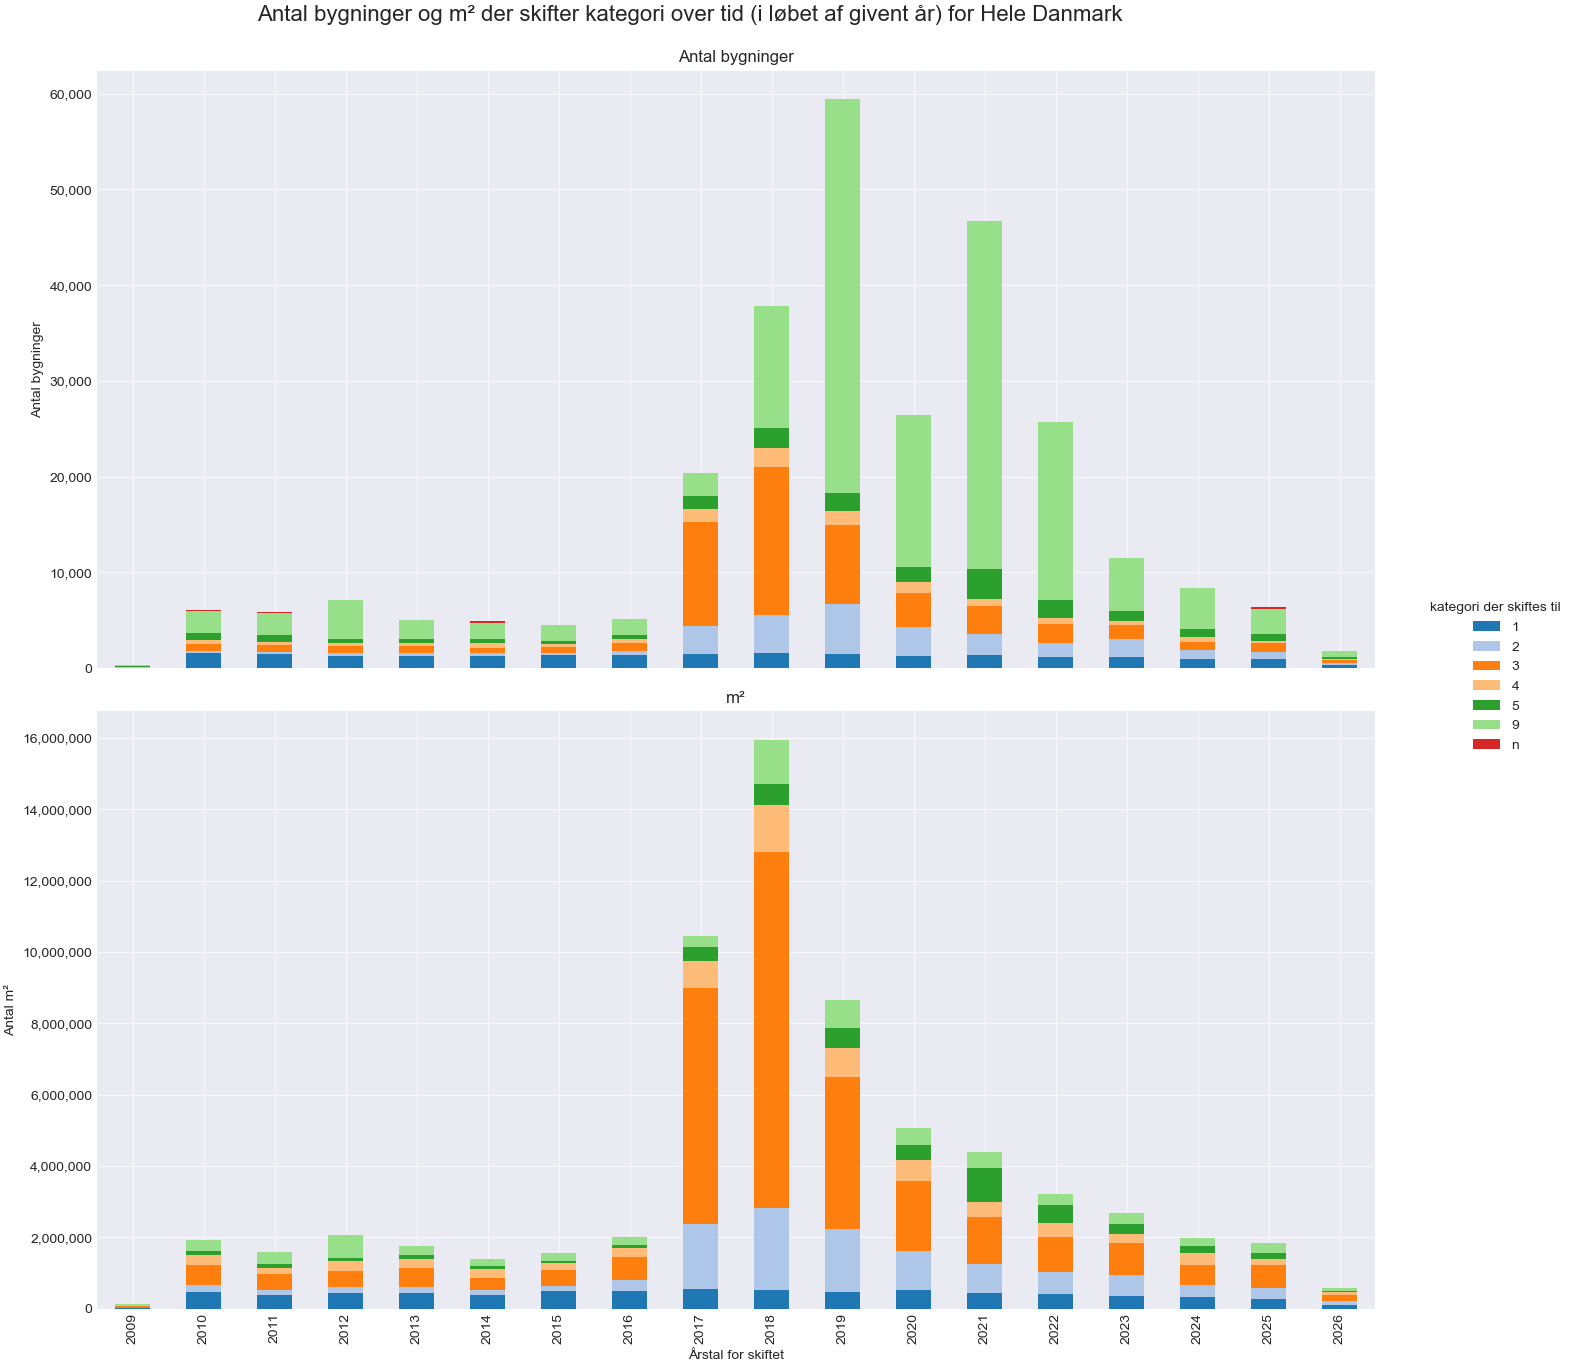

In [18]:
for col in ["to_byg021Anvendelse", "from_byg021Anvendelse"]:
    bbr_processed[col + "_hovedkat"] = bbr_processed[col].astype(str).str[0]

# opret variabel der indikerer om hovedkategorien ændres (dvs. om der skiftes mellem 1,2,3,4,5,6,7,8,9)
bbr_processed["I_D_byg021Anvendelse_hovedkat"] = (
    bbr_processed["to_byg021Anvendelse_hovedkat"] != bbr_processed["from_byg021Anvendelse_hovedkat"]
)

plot_D_kategori_over_tid(bbr_processed, figure_name="Udvikling_i_anvendelseskategori_hele_BBR_nybbr.png")

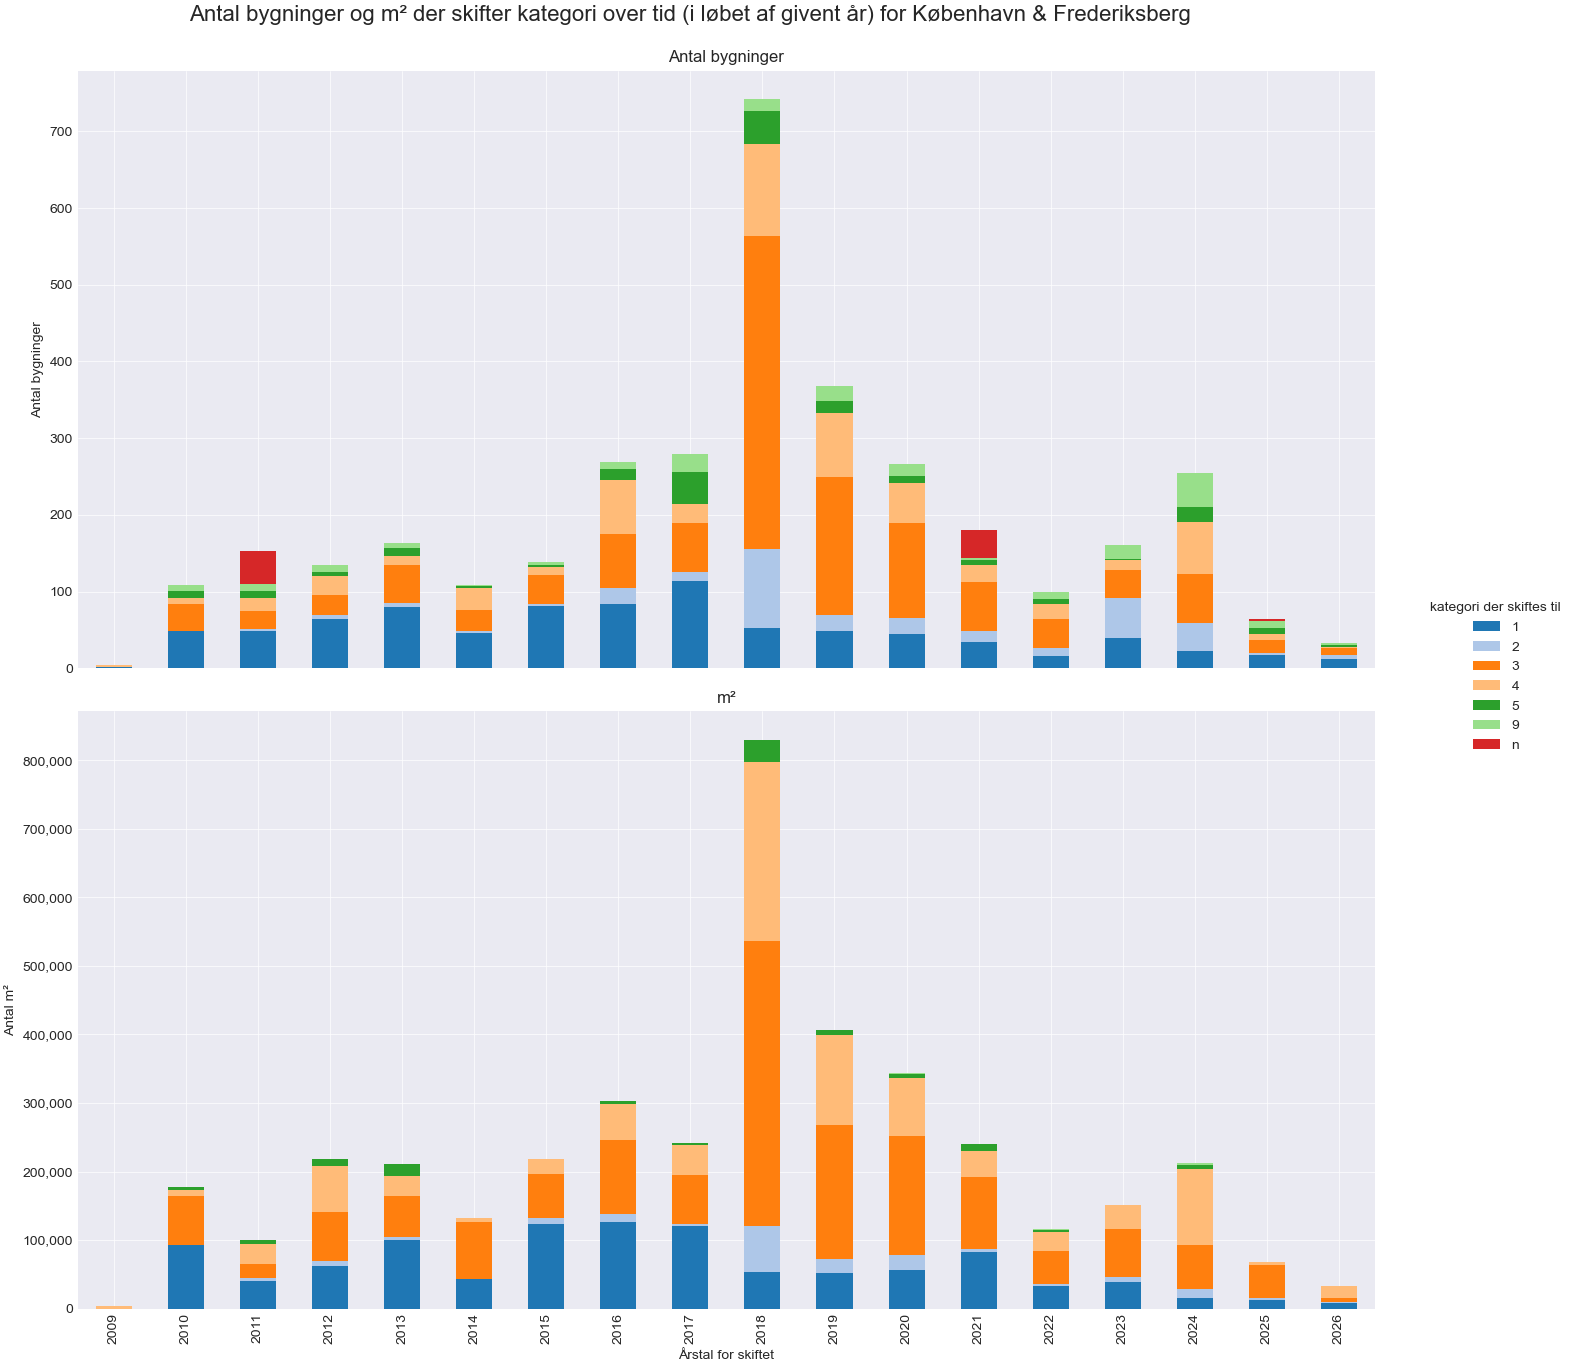

In [19]:
bbr_processed_cph_a_frederiksberg = bbr_processed[bbr_processed['kommunekode'].isin([101,147])].copy()
plot_D_kategori_over_tid(bbr_processed_cph_a_frederiksberg,
                         title='Antal bygninger og m² der skifter kategori over tid (i løbet af givent år) for København & Frederiksberg\n',
                         figure_name="Udvikling_i_anvendelseskategori_KbhFrederiksberg_BBR_nybbr.png")

In [ ]:
# mulig forklaring på diskrepans mellem virkningFra < dato < virkningTil betingelse og opførselsår < dato < virkningTil
print(bbr_processed["virkningFra"].valuecounts())
bbr_processed["virkningFra"].isna()